In [2]:
import sys
from pathlib import Path

# Ajoute la racine du projet (dossier parent de notebooks/) au path Python
root_path = Path.cwd().parent
if str(root_path) not in sys.path:
    sys.path.append(str(root_path))

import matplotlib.pyplot as plt
import numpy as np
from pricing.binomial import binomial_european
from pricing.black_scholes import black_scholes

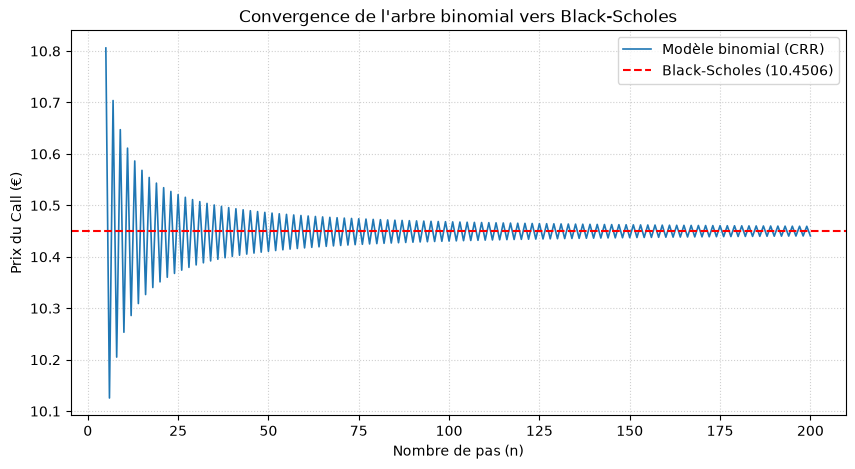

In [3]:
# Paramètres de test
S0 = 100.0
K = 100.0
T = 1.0
r = 0.05
sigma = 0.2
option_type = "call"

# Valeur de référence Black-Scholes
bs_price = black_scholes(S0, K, T, r, sigma, option_type=option_type)

# Convergence binomiale pour n allant de 5 à 200
n_values = np.arange(5, 201)
binomial_prices = [
    binomial_european(S0, K, T, r, sigma, n, option_type=option_type)
    for n in n_values
]

# Tracé
plt.figure(figsize=(10, 5))
plt.plot(n_values, binomial_prices, label="Modèle binomial (CRR)", lw=1.2)
plt.axhline(
    bs_price,
    color="r",
    linestyle="--",
    label=f"Black-Scholes ({bs_price:.4f})",
)
plt.xlabel("Nombre de pas (n)")
plt.ylabel("Prix du Call (€)")
plt.title("Convergence de l'arbre binomial vers Black-Scholes")
plt.legend()
plt.grid(True, linestyle=":", alpha=0.6)
plt.show()

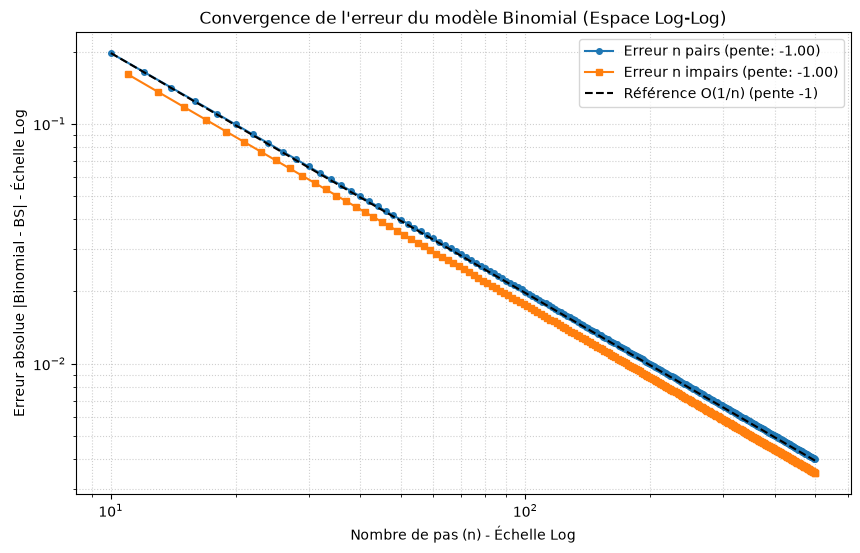

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from pricing.binomial import binomial_european
from pricing.black_scholes import black_scholes

# Paramètres
S0 = 100.0
K = 100.0
T = 1.0
r = 0.05
sigma = 0.2
option_type = "call"

# 1. Valeur de référence Black-Scholes
bs_price = black_scholes(S0, K, T, r, sigma, option_type)

# 2. Génération des grilles N pairs et impairs (de 10 à 500)
n_even = np.arange(10, 502, 2)
n_odd = np.arange(11, 502, 2)

# 3. Calcul des prix et des erreurs absolues
err_even = [abs(binomial_european(S0, K, T, r, sigma, n, option_type) - bs_price) for n in n_even]
err_odd = [abs(binomial_european(S0, K, T, r, sigma, n, option_type) - bs_price) for n in n_odd]

# 4. Régression linéaire dans l'espace Log-Log pour mesurer la pente
# On utilise polyfit(x, y, 1) qui calcule y = a*x + b, a étant la pente.
slope_even, _ = np.polyfit(np.log(n_even), np.log(err_even), 1)
slope_odd, _ = np.polyfit(np.log(n_odd), np.log(err_odd), 1)

# 5. Création de la droite de référence O(1/n) (pente -1)
# On calibre la hauteur sur le premier point de la série paire
A = n_even[0] * err_even[0]
ref_line = A / n_even

# 6. Tracé
plt.figure(figsize=(10, 6))

plt.loglog(n_even, err_even, 'o-', markersize=4, label=f"Erreur n pairs (pente: {slope_even:.2f})")
plt.loglog(n_odd, err_odd, 's-', markersize=4, label=f"Erreur n impairs (pente: {slope_odd:.2f})")
plt.loglog(n_even, ref_line, 'k--', label="Référence O(1/n) (pente -1)")

plt.xlabel("Nombre de pas (n) - Échelle Log")
plt.ylabel("Erreur absolue |Binomial - BS| - Échelle Log")
plt.title("Convergence de l'erreur du modèle Binomial (Espace Log-Log)")
plt.legend()
plt.grid(True, which="both", ls=":", alpha=0.6)

plt.show()